# Chapter 5: Faster Answers: CUPED and Peeking Safely

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Faster Answers: CUPED and Peeking Safely](https://books.sugiv.fyi/lift/faster-answers.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import faster as Fa, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


DAYS, PER_DAY, TAU = 28, 500, 0.3
raw_e, raw_s = Fa.daily_estimates(DAYS, PER_DAY, lift=Fa.GOALS_LIFT, reps=500, seed=3)
cup_e, cup_s = Fa.daily_estimates(DAYS, PER_DAY, lift=Fa.GOALS_LIFT, reps=500, seed=3, use_cuped=True)
raw_power = (Fa.naive_p(raw_e, raw_s) < 0.05).mean(axis=0)     # by day, fixed-horizon test
cup_power = (Fa.naive_p(cup_e, cup_s) < 0.05).mean(axis=0)
glue_num("var_cut", 100 * (1 - (cup_s[:, -1] ** 2).mean() / (raw_s[:, -1] ** 2).mean()))
glue_num("raw_p28", 100 * raw_power[-1])
glue_num("cup_p14", 100 * cup_power[13])
glue_num("cup_p28", 100 * cup_power[-1])

Here's the finding first. Parlo tested **Weekly Goals**, a feature that lets existing learners set a target number of lessons per week. A four-week test would have had about 70% power to detect its true 3% lift. Using each learner's lessons from the *two weeks before the test* to cancel out noise, a technique called **CUPED**, cut the variance by 57%. That gave the test 74% power after **two weeks** and 97% after four. Same learners, same feature, roughly half the time.

The second speed-up is about *when you look*. Everyone peeks at running tests. Peeking with ordinary p-values quietly multiplies false alarms; I'll show by how much. An **always-valid** test fixes that, so you can check every day and stop as soon as the answer is clear. Juno's team uses one as a latency guardrail, and it catches a slow release on its first day.

> **Note**
>
> The numbers come from `lift/sim/faster.py`. Weekly Goals is a new simulated test on existing learners, each with a persistent study habit. The Streak Shield and Juno examples continue from earlier chapters.

## CUPED: subtract what you already knew

Learners differ enormously in how much they study. Some do 3 lessons a fortnight, some do 30. That spread is the noise that makes the Weekly Goals test slow: a 3% lift is small next to it. But most of the spread isn't *new*. A learner who did 30 lessons last fortnight will probably do about 30 this fortnight, feature or no feature.

CUPED (Deng et al., 2013) uses that. For each learner, predict their test-period lessons from their pre-period lessons, and analyse only the part the prediction missed:

$$
Y^{\text{cuped}} = Y - \theta\,(X - \bar X), \qquad \theta = \frac{\operatorname{Cov}(X, Y)}{\operatorname{Var}(X)},
$$

where $X$ is pre-period lessons and $Y$ is test-period lessons. Because $X$ was measured before the coin flip, it can't be affected by the feature, so subtracting it changes the noise but not the effect. The variance falls by a factor of $1 - \rho^2$, where $\rho$ is the correlation between $X$ and $Y$.

Here's one test, 14,000 learners per arm, with CUPED done by hand:

In [3]:
n = 14_000
x_c, y_c = Fa.weekly_goals(n, lift=0.0, seed=11)
x_t, y_t = Fa.weekly_goals(n, lift=Fa.GOALS_LIFT, seed=12)
x, y = np.concatenate([x_c, x_t]), np.concatenate([y_c, y_t])
arm = np.repeat(["control", "goals"], n)

y_adj, theta = Fa.cuped(y, x)                       # theta from both arms pooled
rho = np.corrcoef(x, y)[0, 1]
rows = {}
for name, outcome in [("raw lessons", y), ("CUPED lessons", y_adj)]:
    t, c = outcome[arm == "goals"], outcome[arm == "control"]
    rows[name] = {"lift (lessons)": t.mean() - c.mean(),
                  "standard error": np.sqrt(t.var() / n + c.var() / n)}
print(f"correlation pre vs test: {rho:.2f}, theta = {theta:.2f}")
pd.DataFrame(rows).T

correlation pre vs test: 0.75, theta = 0.77


,lift (lessons),standard error
raw lessons,0.33,0.120
CUPED lessons,0.35,0.079


In [4]:
glue_num("rho_goals", rho)
glue_num("se_ratio", rows["CUPED lessons"]["standard error"] / rows["raw lessons"]["standard error"])

A correlation of 0.75 shrinks the standard error to 0.66 of its raw size. Since the sample you need scales with the variance, that's like getting the test for under half the learners.

If CUPED looks familiar, it should. It's regression adjustment, the same thing as an ANCOVA with the pre-period as a covariate. Pingouin has one, and its answer matches:

In [5]:
df = pd.DataFrame({"lessons": y, "pre_lessons": x, "arm": arm})
pg.ancova(data=df, dv="lessons", between="arm", covar="pre_lessons")

,Source,SS,DF,F,p_unc,np2
0,arm,8.577e+02,1,19.401,1.063e-05,6.925e-04
1,pre_lessons,1.578e+06,1,35697.845,0.000e+00,5.605e-01
2,Residual,1.238e+06,27997,NaN,NaN,NaN


Over 500 reruns of the four-week test, here's what CUPED does to the spread of estimates:

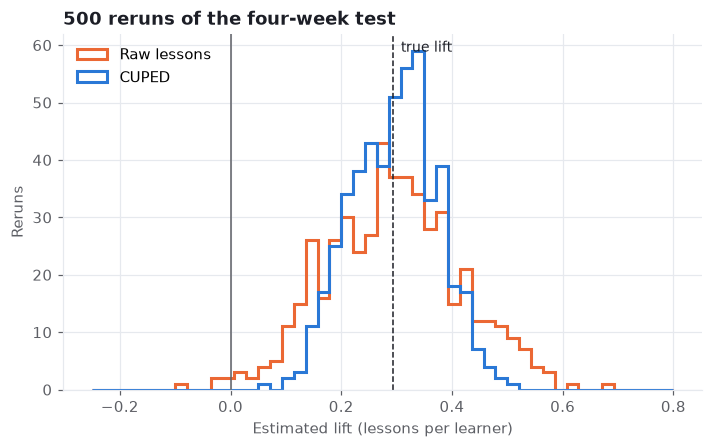

In [6]:
fig, ax = plt.subplots()
bins = np.linspace(-0.25, 0.8, 50)
ax.hist(raw_e[:, -1], bins=bins, histtype="step", linewidth=2, color=style.SERIES[1], label="Raw lessons")
ax.hist(cup_e[:, -1], bins=bins, histtype="step", linewidth=2, color=style.SERIES[0], label="CUPED")
truth = Fa.GOALS_LIFT * Fa.weekly_goals(200_000)[1].mean()
ax.axvline(truth, color=style.INK, linewidth=1, linestyle="--")
ax.axvline(0, color=style.MUTED, linewidth=1)
ax.annotate("true lift", xy=(truth, ax.get_ylim()[1] * 0.95), xytext=(5, 0), textcoords="offset points",
            fontsize=9, color=style.INK)
ax.set(title="500 reruns of the four-week test", xlabel="Estimated lift (lessons per learner)",
       ylabel="Reruns")
ax.legend(loc="upper left")
plt.show()

Both are centred on the truth; CUPED is just much tighter, so far fewer reruns land near zero. That's the whole trick, and it's free: no extra learners, no extra time, one extra column.

### CUPED is only as good as its covariate

Chapter 1 promised that first-week lessons would help the Streak Shield test. Streak Shield is offered on day 8, so first-week lessons are measured before anyone could be affected by it, which is what CUPED needs. They help, but less:

In [7]:
S = Fa.streak_with_pre()
rho_s = np.corrcoef(S.lessons_wk1, S.retained)[0, 1]
anc = pg.ancova(data=S.assign(retained=S.retained.astype(float)), dv="retained",
                between="arm", covar="lessons_wk1")
print(f"correlation of first-week lessons with day-30 retention: {rho_s:.2f}")
print(f"variance cut: {rho_s ** 2:.0%}")
anc

correlation of first-week lessons with day-30 retention: 0.30
variance cut: 9%


,Source,SS,DF,F,p_unc,np2
0,arm,2.246,1,10.425,0.001,3.319e-04
1,lessons_wk1,671.065,1,3114.938,0.000,9.026e-02
2,Residual,6763.992,31397,NaN,NaN,NaN


In [8]:
glue_num("rho_streak", rho_s)
glue_num("cut_streak", 100 * rho_s ** 2)

A correlation of 0.30 cuts the variance by only 9%. Retention is a yes/no outcome, and a week of lessons predicts it only loosely. That's typical: CUPED shines on **continuous habit metrics** (lessons, minutes, revenue, sessions) where the past predicts the future well, and helps much less on rare or binary outcomes, or for brand-new users with no history at all.

Two rules keep CUPED honest. **The covariate must be measured before assignment**: anything measured afterwards might be affected by the treatment, and adjusting for it can create bias. And **estimate $\theta$ on both arms pooled**, as above, so the adjustment doesn't depend on which arm a learner is in.

## Peeking: why looking every day breaks the p-value

The test is running. It's day 6. Someone opens the dashboard and sees p = 0.03. Can they stop?

A p-value promises a 5% false-alarm rate **for one look, at a sample size fixed in advance**. Look every day, and you get 28 chances for noise to cross the line. To see how much that matters, here are 500 **A/A** tests of Weekly Goals (no real effect), checked daily:

In [9]:
aa_e, aa_s = Fa.daily_estimates(DAYS, PER_DAY, lift=0.0, reps=500, seed=1)
p_daily = Fa.naive_p(aa_e, aa_s)
p_always = Fa.msprt(aa_e, aa_s, tau=TAU)
pd.Series({
    "look once, on day 28": (p_daily[:, -1] < 0.05).mean(),
    "look daily, stop at first p below 0.05": (p_daily < 0.05).any(axis=1).mean(),
    "look daily, always-valid p-value": (p_always < 0.05).any(axis=1).mean(),
}).to_frame("false alarms (should be about 5% or less)").style.format("{:.1%}")

,false alarms (should be about 5% or less)
"look once, on day 28",6.6%
"look daily, stop at first p below 0.05",28.0%
"look daily, always-valid p-value",1.4%


In [10]:
glue_num("peek_fpr", 100 * (p_daily < 0.05).any(axis=1).mean())
glue_num("av_fpr", 100 * (p_always < 0.05).any(axis=1).mean())

Daily peeking turns a 5% false-alarm rate into about **28%**. More than one in four tests of a feature that does nothing would be called a win. Here's how it builds up, day by day:

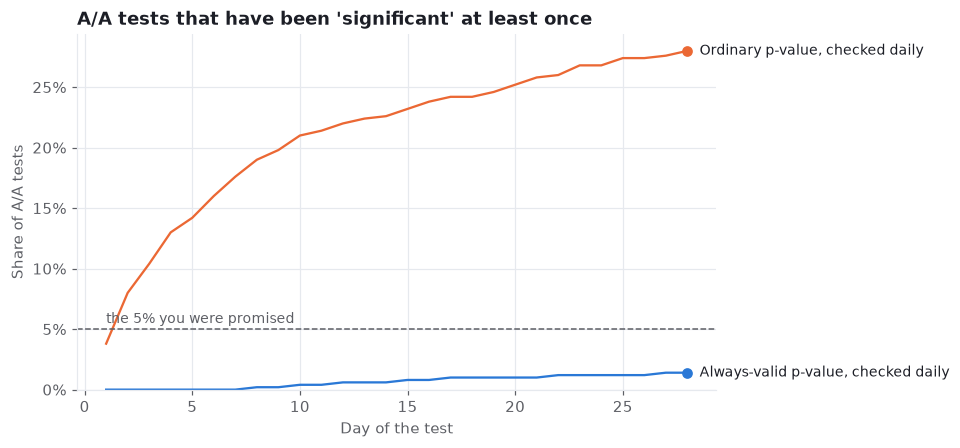

In [11]:
days = np.arange(1, DAYS + 1)
fig, ax = plt.subplots()
for p, label, colour in [(p_daily, "Ordinary p-value, checked daily", style.SERIES[1]),
                         (p_always, "Always-valid p-value, checked daily", style.SERIES[0])]:
    ever = np.maximum.accumulate(p < 0.05, axis=1).mean(axis=0)
    ax.plot(days, ever, color=colour, linewidth=1.5)
    style.label_line_end(ax, days[-1], ever[-1], label, colour)
ax.axhline(0.05, color=style.MUTED, linewidth=1, linestyle="--")
ax.annotate("the 5% you were promised", xy=(1, 0.05), xytext=(0, 4), textcoords="offset points",
            fontsize=9, color=style.MUTED)
ax.set(title="A/A tests that have been 'significant' at least once",
       xlabel="Day of the test", ylabel="Share of A/A tests", ylim=(0, None))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
plt.show()

There are two honest ways out. One is discipline: fix the duration (Chapter 2) and don't act on anything until then. The other is a test **designed** to be checked continuously.

## Always-valid tests

The always-valid p-value above comes from a **mixture sequential probability ratio test (mSPRT)** (Johari et al., 2017). The idea fits in a sentence: at each look, compare how likely the data are if the feature does nothing against how likely they are if it has *some* effect of a plausible size, and stop when the evidence ratio passes $1/\alpha = 20$. A classic result (Ville's inequality) guarantees that a ratio like this, which is fair under "no effect", crosses 20 with probability at most 5% *ever*, however often you check.

The same maths gives a **confidence sequence**: an interval that covers the true lift at every look simultaneously, with 95% probability. Here's one test, with CUPED, watched daily:

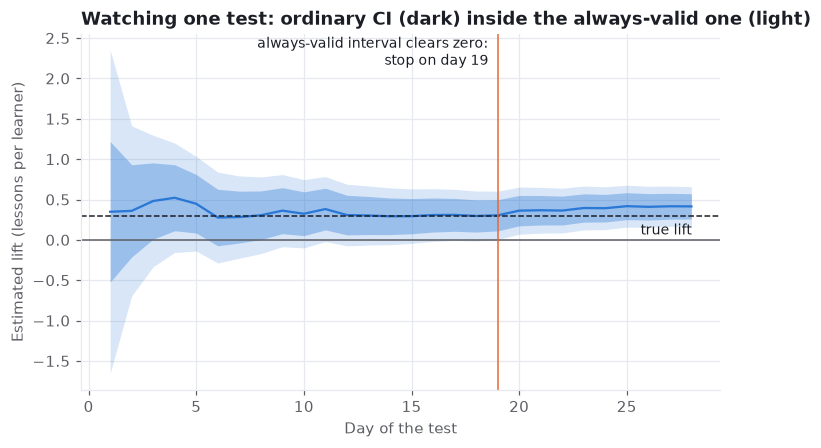

In [12]:
k = 4                                                  # one of the reruns
hw_fixed = 1.96 * cup_s[k]
hw_seq = Fa.confidence_sequence(cup_e[k], cup_s[k], tau=TAU)
fig, ax = plt.subplots()
ax.fill_between(days, cup_e[k] - hw_seq, cup_e[k] + hw_seq, color=style.SERIES[0], alpha=0.18, linewidth=0)
ax.fill_between(days, cup_e[k] - hw_fixed, cup_e[k] + hw_fixed, color=style.SERIES[0], alpha=0.35, linewidth=0)
ax.plot(days, cup_e[k], color=style.SERIES[0], linewidth=1.5)
ax.axhline(0, color=style.MUTED, linewidth=1)
ax.axhline(truth, color=style.INK, linewidth=1, linestyle="--")
stop = np.argmax(cup_e[k] - hw_seq > 0) + 1
ax.axvline(stop, color=style.SERIES[1], linewidth=1)
ax.annotate(f"always-valid interval clears zero:\nstop on day {stop}", xy=(stop, ax.get_ylim()[1] * 0.85),
            xytext=(-6, 0), textcoords="offset points", ha="right", fontsize=9, color=style.INK)
ax.annotate("true lift", xy=(days[-1], truth), xytext=(0, -12), textcoords="offset points",
            ha="right", fontsize=9, color=style.INK)
ax.set(title="Watching one test: ordinary CI (dark) inside the always-valid one (light)",
       xlabel="Day of the test", ylabel="Estimated lift (lessons per learner)")
plt.show()

ord_clear = cup_e[k] - hw_fixed > 0
first_clear = int(np.argmax(ord_clear)) + 1
recross = int(np.argmax(~ord_clear[first_clear:])) + first_clear + 1 if (~ord_clear[first_clear:]).any() else 0
glue_num("ord_first", first_clear)
glue_num("ord_recross", recross)
glue_num("seq_stop", stop)

The always-valid interval is wider than the ordinary one; that's the price of being allowed to look every day. In return, the moment it clears zero you can stop, and the 5% guarantee still holds. Notice what the ordinary interval did: it cleared zero on day 3, and a team peeking at it might have stopped there, but it crossed back on day 6. The always-valid interval waited until day 19, and stayed clear.

<details>
<summary><b>The mSPRT formulas</b></summary>

Let $\hat\Delta_t$ be the estimated lift at look $t$ and $V_t$ its variance (the squared standard error, from CUPED or not). Put a normal "mixture" over plausible true lifts, $\Delta \sim N(0, \tau^2)$. The likelihood ratio of "some effect" against "no effect" is

$$
\Lambda_t = \sqrt{\frac{V_t}{V_t + \tau^2}}\;\exp\!\left(\frac{\tau^2\,\hat\Delta_t^2}{2\,V_t\,(V_t + \tau^2)}\right).
$$

The always-valid p-value is $\min_{s \le t} 1/\Lambda_s$, and the confidence sequence is

$$
\hat\Delta_t \pm \sqrt{\frac{V_t (V_t + \tau^2)}{\tau^2}\left(\log\frac{V_t + \tau^2}{V_t} - 2\log\alpha\right)}.
$$

$\tau$ is a tuning knob: set it near the size of effect you care about (here 0.3 lessons). The guarantee holds for any $\tau$; a good choice just makes the test stop sooner.

</details>

### The price: power on small effects

Always-valid tests aren't free. Across 500 reruns of Weekly Goals:

In [13]:
rows = {}
for name, (e, s) in {"raw": (raw_e, raw_s), "CUPED": (cup_e, cup_s)}.items():
    m = Fa.msprt(e, s, tau=TAU)
    stopped = (m < 0.05).any(axis=1)
    stop_day = np.where(stopped, (m < 0.05).argmax(axis=1) + 1, np.nan)
    rows[name] = {"fixed 28-day test: power": (Fa.naive_p(e[:, -1], s[:, -1]) < 0.05).mean(),
                  "always-valid by day 28: power": stopped.mean(),
                  "median stopping day (when it stops)": np.nanmedian(stop_day)}
seq = pd.DataFrame(rows).T
seq.style.format({"fixed 28-day test: power": "{:.0%}", "always-valid by day 28: power": "{:.0%}",
                  "median stopping day (when it stops)": "{:.0f}"})

,fixed 28-day test: power,always-valid by day 28: power,median stopping day (when it stops)
raw,70%,36%,21
CUPED,97%,81%,14


In [14]:
glue_num("seq_raw", 100 * seq.loc["raw", "always-valid by day 28: power"])
glue_num("seq_cup", 100 * seq.loc["CUPED", "always-valid by day 28: power"])
glue_num("seq_cup_day", seq.loc["CUPED", "median stopping day (when it stops)"])

For a small effect like Weekly Goals, the always-valid test has less power at day 28 than a fixed test that looks once: 36% against 70% without CUPED. CUPED wins most of it back: 81% power, typically stopping around day 14. The two techniques stack.

So I use them for different jobs. **For the decision metric of a small-effect test**, I fix the duration and use CUPED. **For guardrails and anything that could be a disaster**, I use an always-valid test and watch it continuously, because a big harm should stop the test in hours, not weeks. That's exactly the Juno case.

## Juno: a latency guardrail that stops on day one

A new Juno release adds a retrieval step that makes tutoring answers better, and, it turns out, adds 250 ms to every response. Juno's guardrail says responses must not get more than 100 ms slower. The team rolls the release out to a test group of 300 learners a day per arm and watches the guardrail continuously.

Latency has a property that makes CUPED especially strong: most of a learner's latency is **their network and device**, which barely changes from week to week. Their mean latency before the test predicts their latency during it very well:

In [15]:
pre, post = Fa.juno_latency(100_000)
print(f"correlation of pre-test and test latency per learner: {np.corrcoef(pre, post)[0, 1]:.2f}")

correlation of pre-test and test latency per learner: 0.92


The guardrail fires when the always-valid interval's lower end clears the 100 ms margin, that is, when it's sure the release is too slow. Its 5% guarantee is about a slowdown right at the margin, so the table also checks that case:

In [16]:
rows = {}
for name, use_cuped in [("raw latency", False), ("CUPED latency", True)]:
    e, s = Fa.daily_estimates(days=14, per_day=300, lift=Fa.LATENCY_SLOWDOWN, reps=500,
                              use_cuped=use_cuped, seed=5, sampler=Fa.juno_latency)
    fired = (e - Fa.confidence_sequence(e, s, tau=0.2)) > Fa.LATENCY_MARGIN
    e0, s0 = Fa.daily_estimates(days=14, per_day=300, lift=0.0, reps=500,
                                use_cuped=use_cuped, seed=6, sampler=Fa.juno_latency)
    false_fire = ((e0 - Fa.confidence_sequence(e0, s0, tau=0.2)) > Fa.LATENCY_MARGIN).any(axis=1)
    em, sm = Fa.daily_estimates(days=14, per_day=300, lift=Fa.LATENCY_MARGIN, reps=500,
                                use_cuped=use_cuped, seed=7, sampler=Fa.juno_latency)
    at_margin = ((em - Fa.confidence_sequence(em, sm, tau=0.2)) > Fa.LATENCY_MARGIN).any(axis=1)
    rows[name] = {"fired by day 1": fired[:, 0].mean(), "fired by day 3": fired[:, :3].any(axis=1).mean(),
                  "fired with no slowdown": false_fire.mean(),
                  "fired at exactly 100 ms (should be at most 5%)": at_margin.mean()}
lat = pd.DataFrame(rows).T
lat.style.format("{:.0%}")

,fired by day 1,fired by day 3,fired with no slowdown,fired at exactly 100 ms (should be at most 5%)
raw latency,20%,74%,0%,1%
CUPED latency,98%,100%,0%,0%


In [17]:
glue_num("lat_raw_d1", 100 * lat.loc["raw latency", "fired by day 1"])
glue_num("lat_cup_d1", 100 * lat.loc["CUPED latency", "fired by day 1"])
glue_num("lat_margin", 100 * lat["fired at exactly 100 ms (should be at most 5%)"].max())

With CUPED, the guardrail fires on the first day in 98% of runs; without it, 20%. With no slowdown it never fired, and with a slowdown of exactly 100 ms, right at the line, it fired in at most 1% of runs despite being checked every day: within the promised 5%. One day of 300 learners per arm is enough to stop a bad release, because CUPED strips out the network noise and the sequential test lets the team act the moment the evidence is in.

For agent teams this pattern is worth copying wholesale: latency, cost per lesson, error rate and refusal rate are all metrics where each user's past predicts their present, and all are things you want to catch *today*, not at the end of a two-week test.

> **In the wild**
>
> CUPED came out of Bing. Deng, Xu, Kohavi and Walker (Deng et al., 2013) reported that using pre-experiment data cut variance by about half for some Bing metrics: the same power with half the users or half the time. On the peeking side, Johari and colleagues (Johari et al., 2017) describe the always-valid approach behind Optimizely's Stats Engine, motivated by how often users peek at running tests.

## Pitfalls

- **Adjusting for something measured after assignment.** If the treatment can move the covariate, CUPED can bias the result. Use pre-period data only.
- **Expecting CUPED to rescue new-user tests.** No history, no covariate. Use what you know at sign-up (country, platform, acquisition channel); it helps a little.
- **Peeking at ordinary p-values.** Daily checks and early stopping can push false alarms past 25%. Either don't act until the planned end, or use an always-valid test.
- **Using sequential tests for small decision effects without CUPED.** You pay in power. Know the price.
- **Stopping on the guardrail but ignoring it in the readout.** If a guardrail stopped the test, that is the result.

## Exercises

1. **More history.** In `weekly_goals`, the pre-period is one fortnight. Simulate four weeks of pre-period (two draws averaged). How much does the correlation, and the variance cut, improve?
2. **Choosing tau.** Rerun the A/A table with `tau` of 0.1 and 1.0. Do false alarms stay under 5%? How does the median stopping day for the real effect change?
3. **A Bayesian peek.** Using Chapter 4's chance to win, stop each A/A test the first day it exceeds 95%. What's the false-alarm rate? Does a Bayesian dashboard make peeking safe?
4. **Cost guardrail.** Juno's cost per lesson depends heavily on each learner's style (chatty learners cost more). Sketch a CUPED-plus-sequential cost guardrail. What would you use as the covariate?

## Further reading

Deng, Xu, Kohavi and Walker (Deng et al., 2013) introduced CUPED at Microsoft. Johari, Koomen, Pekelis and Walsh (Johari et al., 2017) explain why peeking breaks p-values and describe the always-valid approach Optimizely built on it.